In [1]:
import os
import time
import math
import numpy as np
import random
from pathlib import Path
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns

nsol = 50
alpha = 0.1
r = 0.25
nombre_estudiante = "JeronimoGil"  
ruta_instancias = Path("instancias")
archivos = [f for f in os.listdir(ruta_instancias) if f.endswith(".txt")]
archivos.sort(key=lambda x: int(x.split('_')[1].replace('.txt', '')))
instancias = archivos

### Lectura de las instacias

In [2]:
def leer_instancia(nombre_archivo):
    ruta = ruta_instancias / nombre_archivo

    with open(ruta, "r") as archivo:
        lineas = [linea.strip() for linea in archivo if linea.strip()]
    n, m = map(int, lineas[0].split())

    pesos = []
    adyacencia = []

    for i in range(1, n + 1):
        datos = list(map(int, lineas[i].split()))
        peso = datos[0]
        num_vecinos = datos[1]
        vecinos_originales = datos[2:2 + num_vecinos]

        nodo = i - 1
        vecinos = [
            v for v in vecinos_originales
            if v != nodo
        ]
        pesos.append(peso)
        adyacencia.append(vecinos)

    
    for u in range(n):
        for v in adyacencia[u]:
            if v < 0 or v >= n:
                raise ValueError(
                    f"Instancia {nombre_archivo}: "
                    f"vecino {v} fuera de rango para nodo {u}. "
                    f"Se esperaba un índice entre 0 y {n-1}."
                )

    preasignados = {}
    for i in range(n + 1, n + 1 + m):
        nodo, color = map(int, lineas[i].split())
        if nodo < 0 or nodo >= n:
            raise ValueError(
                f"Instancia {nombre_archivo}: "
                f"nodo preasignado {nodo} fuera de rango."
            )
        if color < 0:
            raise ValueError(
                f"Instancia {nombre_archivo}: "
                f"color preasignado {color} inválido."
            )
        preasignados[nodo] = color

    for u in range(n):
        for v in adyacencia[u]:
            if u not in adyacencia[v]:
                raise ValueError(
                    f"Instancia {nombre_archivo}: "
                    f"la arista ({u},{v}) no es simétrica."
                )

    return {
        "nombre": nombre_archivo,
        "n": n,
        "m": m,
        "pesos": pesos,
        "adyacencia": adyacencia,
        "preasignados": preasignados
    }

### Evaluación factibilidad de la solución

In [3]:
def validar_solucion(solucion, instancia):

    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    preasignados = instancia["preasignados"]

    if isinstance(solucion, dict):
        if len(solucion) != n:
            return False, "La solución no tiene n colores."
        try:
            solucion_lista = [
                solucion[i] for i in range(n)
            ]
        except KeyError:
            return False, "Faltan nodos en la solución."
    elif isinstance(solucion, (list, tuple)):
        solucion_lista = list(solucion)
    else:
        return False, "Formato de solución no válido."
    if len(solucion_lista) != n:
        return False, "La solución no tiene n colores."
    if any(
        c is None or c == -1
        for c in solucion_lista
    ):
        return False, "Existen nodos sin color."
    for c in solucion_lista:

        if not isinstance(c, (int, np.integer)):
            return False, "Existen etiquetas que no son enteras."

        if c < 0:
            return False, "Existe una etiqueta negativa."
    for nodo, color_fijo in preasignados.items():
        if solucion_lista[nodo] != color_fijo:
            return False, (
                f"El nodo {nodo} tenía color preasignado "
                f"{color_fijo}, pero recibió "
                f"{solucion_lista[nodo]}."
            )
    for u in range(n):
        for v in adyacencia[u]:
            if solucion_lista[u] == solucion_lista[v]:
                return False, (
                    f"Conflicto de color entre los nodos "
                    f"{u} y {v}."
                )
    colores_usados = sorted(set(solucion_lista))
    colores_esperados = list(range(len(colores_usados)))
    if colores_usados != colores_esperados:
        return False, (
            f"Las etiquetas no son consecutivas. "
            f"Usadas: {colores_usados}. "
            f"Esperadas: {colores_esperados}."
        )
    return True, "Solución factible."

In [4]:
def evaluar_solucion(solucion, instancia):
    es_valida, mensaje = validar_solucion(solucion, instancia)
    
    if not es_valida:
        n = instancia["n"]
        suma_pesos = sum(instancia["pesos"])
        return n, suma_pesos, 999999.0  

    pesos = instancia["pesos"]
    pesos_por_color = {}

    if isinstance(solucion, dict):
        for nodo, color in solucion.items():
            if color not in pesos_por_color:
                pesos_por_color[color] = 0
            pesos_por_color[color] += pesos[nodo]
    else:
        for nodo, color in enumerate(solucion):
            if color not in pesos_por_color:
                pesos_por_color[color] = 0
            pesos_por_color[color] += pesos[nodo]

    z1 = len(pesos_por_color)
    pesos_colores = list(pesos_por_color.values())
    
    if not pesos_colores:
        return instancia["n"], sum(pesos), 999999.0

    z2 = max(pesos_colores) - min(pesos_colores)
    suma_pesos = sum(pesos)
    valor_combinado = 100.0 * (z1 + (z2 / suma_pesos if suma_pesos > 0 else 0))
    return z1, z2, valor_combinado

In [5]:
def evaluar_objetivo(solucion, instancia):
    pesos = instancia["pesos"]
    pesos_por_color = {}
    for nodo, color in enumerate(solucion):
        if color not in pesos_por_color:
            pesos_por_color[color] = 0
        pesos_por_color[color] += pesos[nodo]
    z1 = len(pesos_por_color)
    pesos_colores = list(pesos_por_color.values())
    if not pesos_colores:
        return 999999.0
    z2 = max(pesos_colores) - min(pesos_colores)
    suma_pesos = sum(pesos)
    objetivo = 100.0 * (
        z1 +
        (z2 / suma_pesos if suma_pesos > 0 else 0)
    )
    return objetivo

### Solución incial

In [6]:
def algoritmo_constructivo(instancia):
    t_inicio = time.time()
    SEED = 29
    random.seed(SEED)
    np.random.seed(SEED)
    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    pesos = instancia["pesos"]
    preasignados = instancia["preasignados"]
    
    if n == 0:
        return {}, 0, 0, 0.0, 0.0
    
    colores = {i: -1 for i in range(n)}
    saturacion = [0] * n
    
    for u, color in preasignados.items():
        colores[u] = color
        
    for u in range(n):
        if colores[u] != -1:
            continue
        colores_vecinos = {colores[v] for v in adyacencia[u] if colores[v] != -1}
        saturacion[u] = len(colores_vecinos)
        
    while any(colores[i] == -1 for i in range(n)):
        candidatos = [i for i in range(n) if colores[i] == -1]
        if not candidatos:
            break
            
        max_sat = max(saturacion[i] for i in candidatos)
        candidatos_sat = [i for i in candidatos if saturacion[i] == max_sat]
        nodo_sel = max(candidatos_sat, key=lambda x: (pesos[x], len(adyacencia[x])))
        
        colores_prohibidos = {colores[v] for v in adyacencia[nodo_sel] if colores[v] != -1}
        colores_usados = set(colores[i] for i in range(n) if colores[i] != -1)
        pesos_por_color = {}
        for c in colores_usados:
            pesos_por_color[c] = sum(pesos[i] for i in range(n) if colores[i] == c)
            
        colores_validos = [c for c in colores_usados if c not in colores_prohibidos]
        
        if colores_validos:
            color_elegido = min(colores_validos, key=lambda c: pesos_por_color[c])
        else:
            color_elegido = 0
            while color_elegido in colores_prohibidos or color_elegido in colores_usados:
                color_elegido += 1
                
        colores[nodo_sel] = color_elegido
        for v in adyacencia[nodo_sel]:
            if colores[v] == -1:
                colores_vecinos_v = {colores[w] for w in adyacencia[v] if colores[w] != -1}
                saturacion[v] = len(colores_vecinos_v)
                
    t_fin = time.time()
    t_ejecucion = round(t_fin - t_inicio, 4)
    t_fin = time.time()
    t_ejecucion = round(t_fin - t_inicio, 4)
    
    z1, z2, f_obj = evaluar_solucion(colores, instancia)
    
    return colores, z1, z2, round(f_obj, 2), t_ejecucion

def algoritmo_grasp(instancia, p_alpha=alpha, p_nsol=nsol):
    inicio = time.perf_counter()
    SEED = 29
    random.seed(SEED)
    np.random.seed(SEED)
    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    pesos = instancia["pesos"]
    preasignados = instancia["preasignados"]
    mejor_solucion = None
    mejor_z1 = float("inf")
    mejor_z2 = float("inf")
    mejor_obj = float("inf")
    for _ in range(p_nsol):
        solucion = [-1] * n
        for nodo, color in preasignados.items():
            solucion[nodo] = color
        colores_vecinos = [set() for _ in range(n)]
        for u in range(n):
            if solucion[u] != -1:
                for v in adyacencia[u]:
                    colores_vecinos[v].add(solucion[u])

      
        while -1 in solucion:
            candidatos = []
            for u in range(n):
                if solucion[u] != -1:
                    continue
                saturacion = len(colores_vecinos[u])
                grado = len(adyacencia[u])
                candidatos.append(
                    (u, saturacion, grado)
                )

            max_sat = max(x[1] for x in candidatos)
            max_grado = max(x[2] for x in candidatos)
            puntuaciones = []
            for u, sat, grado in candidatos:
                sat_norm = (
                    sat / max_sat
                    if max_sat > 0
                    else 0
                )
                grado_norm = (
                    grado / max_grado
                    if max_grado > 0
                    else 0
                )
                score = sat_norm + grado_norm

                puntuaciones.append((u, score))

            max_score = max(score for _, score in puntuaciones)
            min_score = min(score for _, score in puntuaciones)
            umbral = (max_score - p_alpha * (max_score - min_score))
            rcl = [
                u
                for u, score in puntuaciones
                if score >= umbral
            ]

            u = random.choice(rcl)
            prohibidos = colores_vecinos[u]
            color = 0
            while color in prohibidos:
                color += 1
            solucion[u] = color

            for v in adyacencia[u]:
                if solucion[v] == -1:
                    colores_vecinos[v].add(color)
        z1, z2, obj = evaluar_solucion(
            solucion,
            instancia
        )

        if (z1 < mejor_z1 or (z1 == mejor_z1 and z2 < mejor_z2)):
            mejor_solucion = solucion.copy()
            mejor_z1 = z1
            mejor_z2 = z2
            mejor_obj = obj

    tiempo = time.perf_counter() - inicio
    return (
        mejor_solucion,
        mejor_z1,
        mejor_z2,
        mejor_obj,
        tiempo
    )
    
def algoritmo_ruido(instancia, p_r=r, p_nsol=nsol):
    inicio = time.perf_counter()
    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    pesos = instancia["pesos"]
    preasignados = instancia["preasignados"]

    mejor_solucion = None
    mejor_z1 = float("inf")
    mejor_z2 = float("inf")
    mejor_obj = float("inf")
    for _ in range(p_nsol):

        pesos_ruidosos = [
            peso * (
                1 + random.uniform(-p_r, p_r)
            )
            for peso in pesos
        ]

        max_peso = max(pesos_ruidosos)
        solucion = [-1] * n

        for nodo, color in preasignados.items():
            solucion[nodo] = color
        colores_vecinos = [set() for _ in range(n)]
        for u in range(n):
            if solucion[u] != -1:
                for v in adyacencia[u]:
                    colores_vecinos[v].add(solucion[u])

        while -1 in solucion:
            candidatos = []
            for u in range(n):
                if solucion[u] != -1:
                    continue
                saturacion = len(colores_vecinos[u])

                peso_norm = (
                    pesos_ruidosos[u] / max_peso
                    if max_peso > 0
                    else 0
                )
                score = (2.0 * saturacion + peso_norm)
                candidatos.append((u, score))

            u = max(candidatos,key=lambda x: x[1])[0]
            prohibidos = colores_vecinos[u]
            color = 0
            while color in prohibidos:
                color += 1
            solucion[u] = color

            for v in adyacencia[u]:

                if solucion[v] == -1:
                    colores_vecinos[v].add(color)

        
        z1, z2, obj = evaluar_solucion(
            solucion,
            instancia
        )

        if (
            z1 < mejor_z1
            or
            (z1 == mejor_z1 and z2 < mejor_z2)
        ):

            mejor_solucion = solucion.copy()
            mejor_z1 = z1
            mejor_z2 = z2
            mejor_obj = obj

    tiempo = time.perf_counter() - inicio
    return (
        mejor_solucion,
        mejor_z1,
        mejor_z2,
        mejor_obj,
        tiempo
    )

### Guardar resultados

In [7]:
def guardar_resultados_excel(resultados, metodo):
    wb = openpyxl.Workbook()
    wb.remove(wb.active)
    for nom_instancia, datos in resultados.items():
        sol, z1, z2, obj, t_comp = datos
        
        nombre_limpio = str(nom_instancia).replace(".txt", "")
        
        ws = wb.create_sheet(title=nombre_limpio[:31])
        if isinstance(sol, dict):
            lista_colores = [sol[i] for i in sorted(sol.keys())]
        elif isinstance(sol, (list, tuple)):
            lista_colores = list(sol)
        else:
            lista_colores = [0]
            
        ws.append(lista_colores)
        ws.append([int(z1), int(z2), round(float(obj), 2), round(float(t_comp), 2)])
        
    nombre_archivo = f"GCP_JeronimoGil_{metodo}.xlsx"
    wb.save(nombre_archivo)
    print(f"Archivo Excel generado con éxito: {nombre_archivo}")

In [8]:
def guardar_resultados_excel_subcarpeta(resultados, metodo, subcarpeta=""):
    os.makedirs(subcarpeta, exist_ok=True)

    wb = openpyxl.Workbook()
    wb.remove(wb.active)
    
    for nom_instancia, datos in resultados.items():
        sol, z1, z2, obj, t_comp = datos
        nombre_limpio = str(nom_instancia).replace(".txt", "")
        ws = wb.create_sheet(title=nombre_limpio[:31])
        
        if isinstance(sol, dict):
            lista_colores = [sol[i] for i in sorted(sol.keys())]
        elif isinstance(sol, (list, tuple)):
            lista_colores = list(sol)
        else:
            lista_colores = [0]
            
        ws.append(lista_colores)
        ws.append([int(z1), int(z2), round(float(obj), 2), round(float(t_comp), 2)])
        
    nombre_archivo = os.path.join(subcarpeta, f"GCP_JeronimoGil_{metodo}.xlsx")
    wb.save(nombre_archivo)
    print(f"Archivo Excel generado: {nombre_archivo}")

### Vecindarios

In [9]:
def obtener_metricas_colores(solucion_actual, pesos):
    pesos_color = {}
    frecuencia = {}
    for i, c in enumerate(solucion_actual):
        pesos_color[c] = pesos_color.get(c, 0) + pesos[i]
        frecuencia[c] = frecuencia.get(c, 0) + 1
        
    c_pesado = max(pesos_color, key=pesos_color.get)
    c_liviano = min(pesos_color, key=pesos_color.get)
    return c_pesado, c_liviano, pesos_color, frecuencia

def reparar_etiquetas(solucion, instancia):
    solucion_reparada = list(solucion)
    preasignados = instancia["preasignados"]
    colores_actuales = sorted(set(solucion_reparada))
    n_colores = len(colores_actuales)
    colores_fijos = set(preasignados.values())

    if any(
        color < 0 or color >= n_colores
        for color in colores_fijos
    ):
        return solucion_reparada

    etiquetas_disponibles = [
        color
        for color in range(n_colores)
        if color not in colores_fijos
    ]
    colores_movibles = [
        color
        for color in colores_actuales
        if color not in colores_fijos
    ]

    mapa_colores = {}

    for color in colores_fijos:
        mapa_colores[color] = color

    for color_viejo, color_nuevo in zip(
        colores_movibles,
        etiquetas_disponibles
    ):
        mapa_colores[color_viejo] = color_nuevo

    for nodo in range(len(solucion_reparada)):
        color_actual = solucion_reparada[nodo]
        solucion_reparada[nodo] = (
            mapa_colores[color_actual]
        )
    return solucion_reparada
    
def construir_estructuras_coloreo(solucion, instancia):
    n = instancia["n"]
    adyacencia = instancia["adyacencia"]

    colores_nodos = {}
    for v in range(n):
        c = solucion[v]
        if c not in colores_nodos:
            colores_nodos[c] = []
        colores_nodos[c].append(v)
    conteo_vecinos_color = [dict() for _ in range(n)]

    for v in range(n):
        conteos = conteo_vecinos_color[v]
        for u in adyacencia[v]:
            c = solucion[u]
            conteos[c] = conteos.get(c, 0) + 1
    colores_vecinos = [
        set(conteo_vecinos_color[v].keys())
        for v in range(n)
    ]
    grados = [
        len(adyacencia[v])
        for v in range(n)
    ]
    return (
        colores_nodos,
        conteo_vecinos_color,
        colores_vecinos,
        grados
    )

def es_movimiento_1move_valido(nodo,nuevo_color,solucion,conteo_vecinos_color):
    return conteo_vecinos_color[nodo].get(nuevo_color, 0) == 0

def es_movimiento_swap_valido(i,j,solucion,conteo_vecinos_color,adyacencia):
    color_i = solucion[i]
    color_j = solucion[j]
    if color_i == color_j:
        return False

    conflictos_i = conteo_vecinos_color[i].get(color_j, 0)
    conflictos_j = conteo_vecinos_color[j].get(color_i, 0)
    if j in adyacencia[i]:
        conflictos_i -= 1
    if i in adyacencia[j]:
        conflictos_j -= 1
    return conflictos_i == 0 and conflictos_j == 0

#### Vecindario 1 - 1-Move

In [10]:
def get_N1_neighbors(solucion_actual, instancia):
    n = instancia["n"]
    pesos = instancia["pesos"]
    preasignados = set(instancia["preasignados"].keys())
    c_pesado, c_liviano, _, frecuencia = \
        obtener_metricas_colores(
            solucion_actual,
            pesos
        )
    colores_unicos = list(frecuencia.keys())
    (
        colores_nodos,
        conteo_vecinos_color,
        colores_vecinos,
        grados
    ) = construir_estructuras_coloreo(
        solucion_actual,
        instancia
    )
    candidatos = [
        v for v in range(n)
        if v not in preasignados
    ]
    candidatos.sort(
        key=lambda v: (
            solucion_actual[v] == c_pesado,
            grados[v]
        ),
        reverse=True
    )

    for nodo in candidatos:
        color_actual = solucion_actual[nodo]
        colores_candidatos = []
        if c_liviano != color_actual:
            colores_candidatos.append(c_liviano)
        for c in colores_unicos:
            if c != color_actual and c != c_liviano:
                colores_candidatos.append(c)
        for nuevo_color in colores_candidatos:
            if conteo_vecinos_color[nodo].get(
                nuevo_color, 0
            ) != 0:
                continue
            vecino_sol = list(solucion_actual)
            vecino_sol[nodo] = nuevo_color
            yield vecino_sol

#### Vecindario 2 - Swap

In [11]:
def get_N2_neighbors(solucion_actual, instancia):
    n = instancia["n"]
    pesos = instancia["pesos"]
    adyacencia = instancia["adyacencia"]
    preasignados = set(instancia["preasignados"].keys())

    c_pesado, c_liviano, _, _ = \
        obtener_metricas_colores(
            solucion_actual,
            pesos
        )
    colores_importantes = {
        c_pesado,
        c_liviano
    }

    (
        colores_nodos,
        conteo_vecinos_color,
        colores_vecinos,
        grados
    ) = construir_estructuras_coloreo(
        solucion_actual,
        instancia
    )

    candidatos = [
        v for v in range(n)
        if v not in preasignados
    ]
    candidatos.sort(
        key=lambda v: (
            solucion_actual[v] in colores_importantes,
            grados[v]
        ),
        reverse=True
    )

    for pos_i in range(len(candidatos)):

        i = candidatos[pos_i]
        color_i = solucion_actual[i]

        for pos_j in range(pos_i + 1, len(candidatos)):

            j = candidatos[pos_j]
            color_j = solucion_actual[j]

            if color_i == color_j:
                continue

            if (
                color_i not in colores_importantes
                and color_j not in colores_importantes
            ):
                continue

            if not es_movimiento_swap_valido(
                i,
                j,
                solucion_actual,
                conteo_vecinos_color,
                adyacencia
            ):
                continue

            vecino_sol = list(solucion_actual)
            vecino_sol[i] = color_j
            vecino_sol[j] = color_i
            yield vecino_sol

#### Vecindario 3 - Recolaración

In [12]:
def get_N3_neighbors(solucion_actual, instancia):
    n = instancia["n"]
    adyacencia = instancia["adyacencia"]
    preasignados = set(instancia["preasignados"].keys())
    MAX_PARES_POR_COLOR = 5
    MAX_COLORES_DESTINO = 3

    colores = sorted(set(solucion_actual))
    if not colores:
        return

    nodos_por_color = {}
    for nodo in range(n):
        if nodo in preasignados:
            continue
        color = solucion_actual[nodo]
        if color not in nodos_por_color:
            nodos_por_color[color] = []
        nodos_por_color[color].append(nodo)
    for color_origen in sorted(nodos_por_color.keys()):
        nodos = nodos_por_color[color_origen]
        if len(nodos) < 2:
            continue
        pares = []
        for i in range(len(nodos)):
            for j in range(i + 1, len(nodos)):
                pares.append(
                    (nodos[i], nodos[j])
                )
                if len(pares) >= MAX_PARES_POR_COLOR:
                    break
            if len(pares) >= MAX_PARES_POR_COLOR:
                break

        for v1, v2 in pares:
            colores_factibles_v1 = []
            for color_destino in colores:
                if color_destino == color_origen:
                    continue
                conflicto = False
                for vecino in adyacencia[v1]:
                    if vecino == v2:
                        continue
                    if solucion_actual[vecino] == color_destino:
                        conflicto = True
                        break
                if not conflicto:
                    colores_factibles_v1.append(
                        color_destino
                    )
            colores_factibles_v2 = []
            for color_destino in colores:
                if color_destino == color_origen:
                    continue
                conflicto = False
                for vecino in adyacencia[v2]:
                    if vecino == v1:
                        continue
                    if solucion_actual[vecino] == color_destino:
                        conflicto = True
                        break
                if not conflicto:
                    colores_factibles_v2.append(
                        color_destino
                    )
            colores_factibles_v1 = (
                colores_factibles_v1[
                    :MAX_COLORES_DESTINO
                ]
            )
            colores_factibles_v2 = (
                colores_factibles_v2[
                    :MAX_COLORES_DESTINO
                ]
            )
            if (
                not colores_factibles_v1
                or not colores_factibles_v2
            ):
                continue
            for color_v1 in colores_factibles_v1:
                for color_v2 in colores_factibles_v2:
                    if (
                        v2 in adyacencia[v1]
                        and color_v1 == color_v2
                    ):
                        continue

                    vecino_sol = list(solucion_actual)
                    vecino_sol[v1] = color_v1
                    vecino_sol[v2] = color_v2

                    factible = True
                    for nodo in (v1, v2):
                        color_nuevo = vecino_sol[nodo]
                        for vecino in adyacencia[nodo]:
                            if vecino == v1 or vecino == v2:
                                continue
                            if vecino_sol[vecino] == color_nuevo:
                                factible = False
                                break
                        if not factible:
                            break
                    if not factible:
                        continue

                    vecino_sol = reparar_etiquetas(
                        vecino_sol,
                        instancia
                    )
                    yield vecino_sol

### VND

In [13]:
def variable_neighborhood_descent(sol_inicial, instancia, vecindarios, tiempo_max_segundos=3600):
    t_inicio = time.time()
    mejor_solucion = list(sol_inicial)
    
    _, _, mejor_f = evaluar_solucion(mejor_solucion, instancia)
    
    k = 0
    
    while k < len(vecindarios):
        if (time.time() - t_inicio) > tiempo_max_segundos:
            print("Tiempo límite alcanzado en VND.")
            break
            
        mejora_encontrada = False
        vecindario_actual = vecindarios[k]
        for sol_vecina in vecindario_actual(mejor_solucion, instancia):
            _, _, f_vecina = evaluar_solucion(sol_vecina, instancia)
            
            if f_vecina < mejor_f:
                mejor_solucion = sol_vecina
                mejor_f = f_vecina
                mejora_encontrada = True
                break 
                
        if mejora_encontrada:
            k = 0
        else:
            k += 1
            
    t_ejecucion = time.time() - t_inicio
    return mejor_solucion, mejor_f, t_ejecucion

#### Escogencia del orden de vecindarios para el VND

In [14]:
archivos_instancias = [f"GCP_{i}.txt" for i in range(1, 20)]

configuraciones_vnd = [
    ("VND-123", [get_N1_neighbors, get_N2_neighbors, get_N3_neighbors]),
    ("VND-132", [get_N1_neighbors, get_N3_neighbors, get_N2_neighbors]),
    ("VND-213", [get_N2_neighbors, get_N1_neighbors, get_N3_neighbors]),
    ("VND-231", [get_N2_neighbors, get_N3_neighbors, get_N1_neighbors]),
    ("VND-312", [get_N3_neighbors, get_N1_neighbors, get_N2_neighbors]),
    ("VND-321", [get_N3_neighbors, get_N2_neighbors, get_N1_neighbors])
]

resultados_globales = {nombre: {} for nombre, _ in configuraciones_vnd}

print("Iniciando ejecución masiva optimizada para todas las variantes VND...")
SEED = 123
random.seed(SEED)
for archivo in archivos_instancias:
    try:
        instancia = leer_instancia(archivo) 
        sol_dict, _, _, f_ini, _ = algoritmo_ruido(instancia)
        sol_inicial_lista = [sol_dict[i] for i in range(instancia["n"])]
        
        print(f"\n{archivo} | FO Base (Ruido): {f_ini:.2f}")
        for nombre_metodo, lista_vecindarios in configuraciones_vnd:
            t0 = time.time()
            
            sol_final, f_final, t_exe_vnd = variable_neighborhood_descent(
                sol_inicial_lista, 
                instancia, 
                lista_vecindarios
            )
            
            z1_fin, z2_fin, f_obj_fin = evaluar_solucion(sol_final, instancia)
            mejora = f_ini - f_obj_fin
            
            resultados_globales[nombre_metodo][archivo] = (sol_final, z1_fin, z2_fin, f_obj_fin, t_exe_vnd)
            print(f"{nombre_metodo} | FO Final: {f_obj_fin:.2f} | Mejora: {mejora:.2f} | Tiempo: {t_exe_vnd:.3f}s")
            
    except FileNotFoundError:
        print(f"Advertencia: No se encontró el archivo {archivo}.")
    except Exception as e:
        print(f"Error procesando {archivo}: {e}")


print("\nGenerando reportes Excel en la subcarpeta")
for nombre_metodo, resultados in resultados_globales.items():
    if resultados:
        guardar_resultados_excel_subcarpeta(resultados, nombre_metodo, subcarpeta="soluciones_vnds")

Iniciando ejecución masiva optimizada para todas las variantes VND...

GCP_1.txt | FO Base (Ruido): 430.64
VND-123 | FO Final: 404.28 | Mejora: 26.36 | Tiempo: 0.002s
VND-132 | FO Final: 404.28 | Mejora: 26.36 | Tiempo: 0.002s
VND-213 | FO Final: 403.79 | Mejora: 26.85 | Tiempo: 0.001s
VND-231 | FO Final: 403.79 | Mejora: 26.85 | Tiempo: 0.001s
VND-312 | FO Final: 416.31 | Mejora: 14.33 | Tiempo: 0.001s
VND-321 | FO Final: 403.79 | Mejora: 26.85 | Tiempo: 0.002s

GCP_2.txt | FO Base (Ruido): 426.03
VND-123 | FO Final: 406.10 | Mejora: 19.93 | Tiempo: 0.001s
VND-132 | FO Final: 406.10 | Mejora: 19.93 | Tiempo: 0.001s
VND-213 | FO Final: 405.44 | Mejora: 20.59 | Tiempo: 0.001s
VND-231 | FO Final: 405.44 | Mejora: 20.59 | Tiempo: 0.001s
VND-312 | FO Final: 406.10 | Mejora: 19.93 | Tiempo: 0.001s
VND-321 | FO Final: 405.44 | Mejora: 20.59 | Tiempo: 0.001s

GCP_3.txt | FO Base (Ruido): 900.00
VND-123 | FO Final: 900.00 | Mejora: 0.00 | Tiempo: 0.002s
VND-132 | FO Final: 900.00 | Mejora: 0.0

##### GAP

In [15]:
nombre_base = "GCP_JeronimoGil"

metodos = [
    "VND-123",
    "VND-132",
    "VND-231",
    "VND-213",
    "VND-312",
    "VND-321",
]

carpeta_vnds = Path("soluciones_vnds")

archivos = {
    "VND-123": carpeta_vnds / f"{nombre_base}_VND-123.xlsx",
    "VND-132": carpeta_vnds / f"{nombre_base}_VND-132.xlsx",
    "VND-231": carpeta_vnds / f"{nombre_base}_VND-231.xlsx",
    "VND-213": carpeta_vnds / f"{nombre_base}_VND-213.xlsx",
    "VND-312": carpeta_vnds / f"{nombre_base}_VND-312.xlsx",
    "VND-321": carpeta_vnds / f"{nombre_base}_VND-321.xlsx"
}

bks = {}
with open("BKS2.txt", "r", encoding="utf-8") as archivo:
    for i, linea in enumerate(archivo, start=1):
        linea = linea.strip()

        if linea:
            bks[f"GCP_{i}"] = float(linea.replace(",", "."))

datos = {}
for metodo, nombre_archivo in archivos.items():
    ruta = Path(nombre_archivo)
    if not ruta.exists():
        print(f"\nADVERTENCIA: no se encontró {nombre_archivo}")
        continue
    wb = openpyxl.load_workbook(
        nombre_archivo,
        data_only=True
    )
    datos[metodo] = {}
    for ws in wb.worksheets:

        instancia = ws.title
        fila = list(
            ws.iter_rows(
                min_row=2,
                max_row=2,
                values_only=True
            )
        )[0]

        z1 = fila[0]
        z2 = fila[1]
        fo = float(fila[2])
        tiempo = float(fila[3])
        bks_valor = bks[instancia]
        gap = 100 * (fo - bks_valor) / bks_valor
        datos[metodo][instancia] = {
            "z1": z1,
            "z2": z2,
            "fo": fo,
            "tiempo": tiempo,
            "bks": bks_valor,
            "gap": gap
        }

print("\nArchivos cargados correctamente.")

instancias = [f"GCP_{i}" for i in range(1, 20)]

tabla_gap = pd.DataFrame(
    index=instancias,
    columns=list(datos.keys()),
    dtype=float
)

for metodo in datos:

    for instancia in instancias:

        if instancia in datos[metodo]:

            tabla_gap.loc[
                instancia,
                metodo
            ] = datos[metodo][instancia]["gap"]

tabla_gap.loc["PROMEDIO"] = tabla_gap.mean()
print("GAP (%)")

display(tabla_gap.round(2))


Archivos cargados correctamente.
GAP (%)


,VND-123,VND-132,VND-231,VND-213,VND-312,VND-321
GCP_1,0.12,0.12,0.00,0.00,3.10,0.00
GCP_2,0.57,0.57,0.41,0.41,0.57,0.41
GCP_3,0.00,0.00,0.00,0.00,0.00,0.00
GCP_4,0.02,0.02,0.03,0.03,0.02,0.02
GCP_5,0.01,0.01,0.02,0.02,0.03,0.03
GCP_6,0.06,0.06,0.06,0.06,0.06,0.06
GCP_7,0.79,0.79,1.19,1.15,0.62,1.34
GCP_8,0.23,0.23,1.26,0.24,0.05,1.15
GCP_9,0.05,0.05,0.31,0.29,0.04,0.16
GCP_10,0.03,0.03,0.27,0.28,0.04,0.26


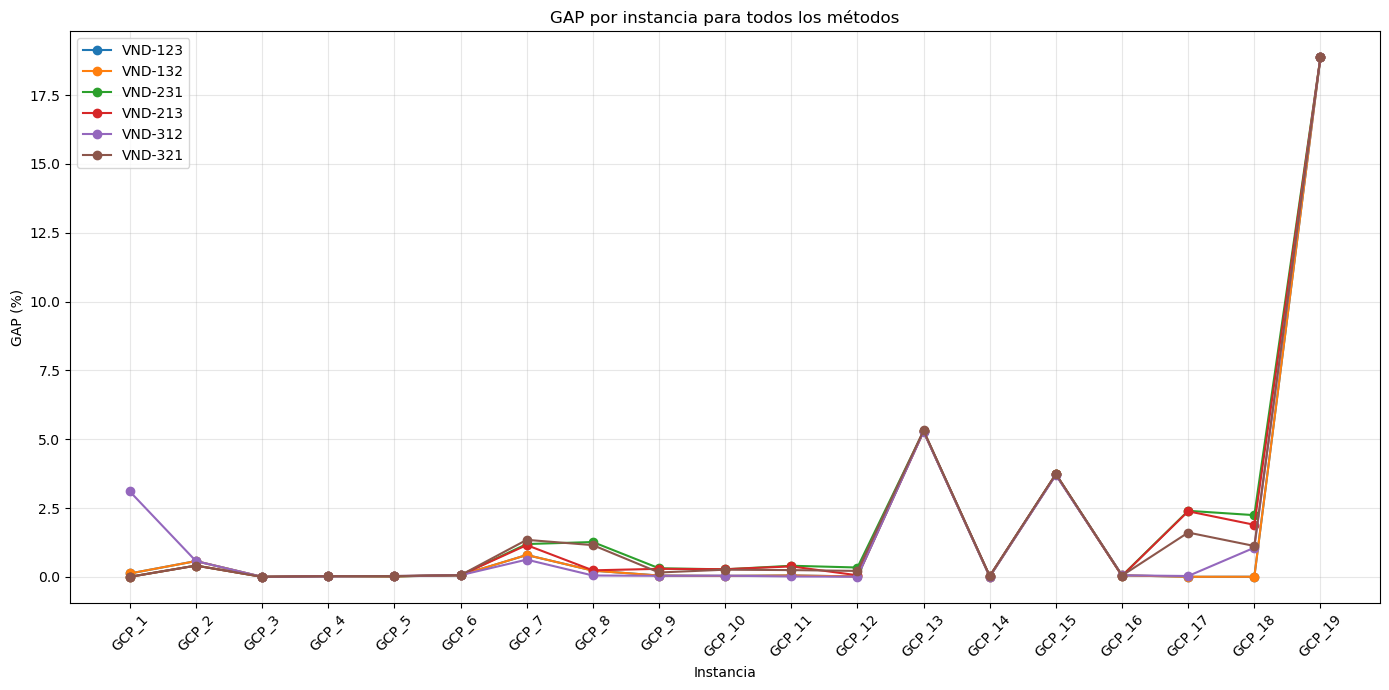

In [16]:
plt.figure(figsize=(14, 7))

for metodo in tabla_gap.columns:

    plt.plot(
        instancias,
        tabla_gap.loc[instancias, metodo],
        marker="o",
        label=metodo
    )

plt.xlabel("Instancia")
plt.ylabel("GAP (%)")
plt.title("GAP por instancia para todos los métodos")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

##### Tiempos de computo

In [17]:
tabla_tiempo = pd.DataFrame(
    index=instancias,
    columns=list(datos.keys()),
    dtype=float
)

for metodo in datos:

    for instancia in instancias:

        if instancia in datos[metodo]:

            tabla_tiempo.loc[
                instancia,
                metodo
            ] = datos[metodo][instancia]["tiempo"]

tabla_tiempo.loc["PROMEDIO"] = tabla_tiempo.mean()

print("TIEMPO DE CÓMPUTO (s)")

display(tabla_tiempo.round(4))

TIEMPO DE CÓMPUTO (s)


,VND-123,VND-132,VND-231,VND-213,VND-312,VND-321
GCP_1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
GCP_2,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
GCP_3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
GCP_4,1.3700,1.6300,1.9400,1.7700,4.9700,3.4400
GCP_5,2.3700,2.7300,2.1300,1.4000,2.4100,2.5900
GCP_6,0.0200,0.0200,0.0200,0.0200,0.0200,0.0200
GCP_7,0.6100,0.6100,7.6500,5.7100,1.3900,3.3300
GCP_8,1.3900,1.4000,2.6400,10.3300,1.8500,3.5600
GCP_9,4.5000,4.8100,18.1100,24.5700,39.4700,20.8200
GCP_10,4.4300,4.5000,13.4300,13.9900,29.8800,31.4300


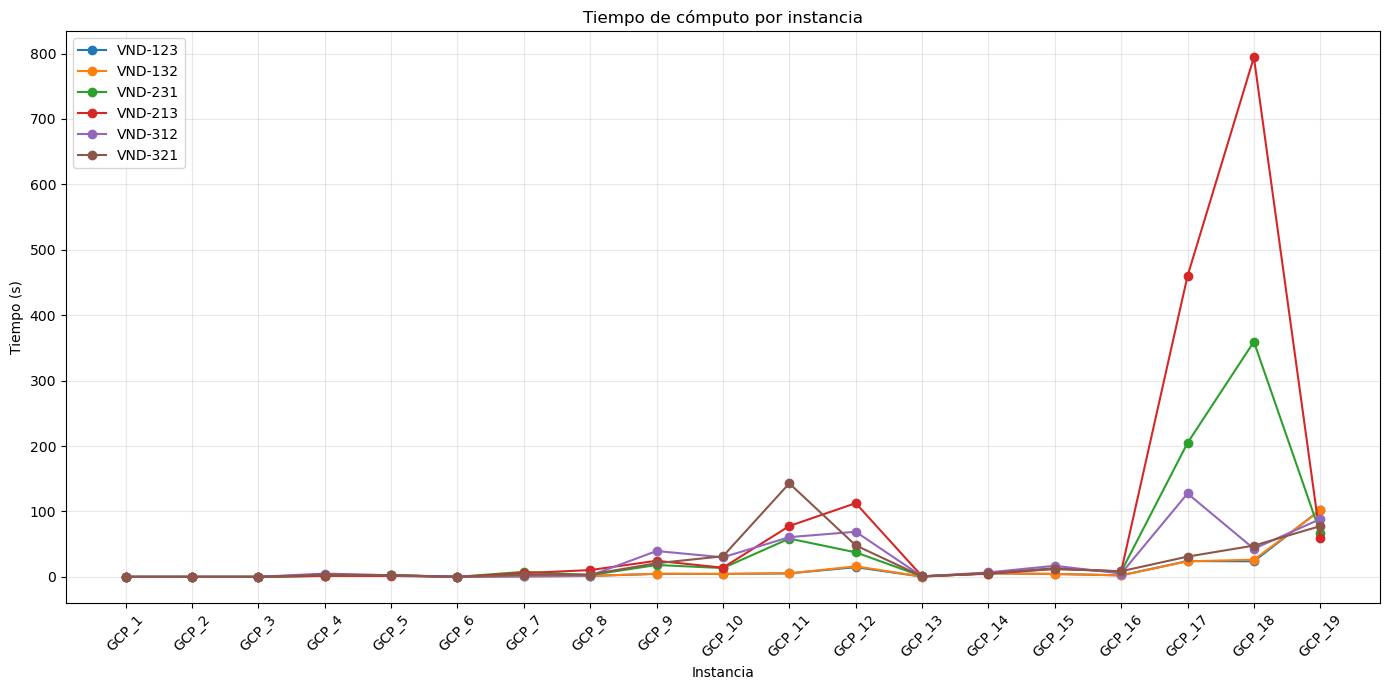

In [18]:
plt.figure(figsize=(14, 7))

for metodo in tabla_tiempo.columns:

    plt.plot(
        instancias,
        tabla_tiempo.loc[instancias, metodo],
        marker="o",
        label=metodo
    )

plt.xlabel("Instancia")
plt.ylabel("Tiempo (s)")
plt.title("Tiempo de cómputo por instancia")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Mejor VND 

In [19]:
archivos_instancias = [f"GCP_{i}.txt" for i in range(1, 20)]

resultados_vnd = {}
metodo_actual = "VND" 
lista_vecindarios = [get_N1_neighbors, get_N2_neighbors, get_N3_neighbors]

print(f"Iniciando ejecución masiva para el método: {metodo_actual}")
SEED = 123
random.seed(SEED)
for archivo in archivos_instancias:
    try:
        instancia = leer_instancia(archivo) 
        sol_dict, z1_ini, z2_ini, f_ini, _ = algoritmo_ruido(instancia)
        sol_inicial_lista = [sol_dict[i] for i in range(instancia["n"])]
        
        t0 = time.time()
        sol_final, f_final, t_exe_vnd = variable_neighborhood_descent(
            sol_inicial_lista, 
            instancia, 
            lista_vecindarios
        )
        z1_fin, z2_fin, f_obj_fin = evaluar_solucion(sol_final, instancia)
        resultados_vnd[archivo] = (sol_final, z1_fin, z2_fin, f_obj_fin, t_exe_vnd)
        
        mejora = f_ini - f_obj_fin
        print(f"{archivo} | FO Inicial: {f_ini:.2f} -> FO Final: {f_obj_fin:.2f} | Mejora: {mejora:.2f}")
        
    except FileNotFoundError:
        print(f"Advertencia: No se encontró el archivo {archivo}. Saltando...")
    except Exception as e:
        print(f"Error procesando {archivo}: {e}")

# 7. Llamar a tu función de guardado
print("\nGenerando reporte en Excel")
guardar_resultados_excel(resultados_vnd, metodo_actual)

Iniciando ejecución masiva para el método: VND
GCP_1.txt | FO Inicial: 430.64 -> FO Final: 404.28 | Mejora: 26.36
GCP_2.txt | FO Inicial: 426.03 -> FO Final: 406.10 | Mejora: 19.93
GCP_3.txt | FO Inicial: 900.00 -> FO Final: 900.00 | Mejora: 0.00
GCP_4.txt | FO Inicial: 7303.46 -> FO Final: 7302.06 | Mejora: 1.41
GCP_5.txt | FO Inicial: 7303.45 -> FO Final: 7301.75 | Mejora: 1.70
GCP_6.txt | FO Inicial: 1906.25 -> FO Final: 1906.25 | Mejora: 0.00
GCP_7.txt | FO Inicial: 824.56 -> FO Final: 806.38 | Mejora: 18.18
GCP_8.txt | FO Inicial: 822.03 -> FO Final: 802.13 | Mejora: 19.90
GCP_9.txt | FO Inicial: 4928.71 -> FO Final: 4902.33 | Mejora: 26.38
GCP_10.txt | FO Inicial: 4925.92 -> FO Final: 4901.84 | Mejora: 24.08
GCP_11.txt | FO Inicial: 4941.64 -> FO Final: 4902.94 | Mejora: 38.70
GCP_12.txt | FO Inicial: 4936.17 -> FO Final: 4901.13 | Mejora: 35.04
GCP_13.txt | FO Inicial: 2004.89 -> FO Final: 2001.20 | Mejora: 3.69
GCP_14.txt | FO Inicial: 1404.23 -> FO Final: 1401.46 | Mejora: 2.7

### Metaheuristica hibrida

In [20]:
def perturbar_solucion(solucion, instancia, grado_perturbacion=0.15):
    n = instancia["n"]
    preasignados = instancia["preasignados"]
    sol_perturbada = list(solucion)
    colores_disponibles = list(set(solucion))
    
    num_nodos_alterar = max(1, int(n * grado_perturbacion))
    
    # Solo podemos perturbar nodos que NO están preasignados
    candidatos = [i for i in range(n) if i not in preasignados]
    
    if not candidatos:
        return sol_perturbada
        
    nodos_a_cambiar = random.sample(candidatos, min(num_nodos_alterar, len(candidatos)))
    
    for nodo in nodos_a_cambiar:
        color_actual = sol_perturbada[nodo]
        opciones = [c for c in colores_disponibles if c != color_actual]
        if opciones:
            sol_perturbada[nodo] = random.choice(opciones)
            
    # Reparar etiquetas para mantener factibilidad de los índices
    return reparar_etiquetas(sol_perturbada, instancia)

def metaheuristico_hibrido(instancia, vecindarios, num_inicios=3, iteraciones_ils=10, 
                           grado_perturbacion=0.15, temp_inicial=50.0, alpha=0.85, 
                           tiempo_max_segundos=180):
    t_inicio = time.time()
    mejor_solucion_global = None
    mejor_f_global = float('inf')
    
    
    for inicio in range(num_inicios):
        if (time.time() - t_inicio) > tiempo_max_segundos:
            break
            
       
        sol_base, _, _, _, _ = algoritmo_ruido(instancia, p_r=0.25, p_nsol=50) 
        sol_actual = list(sol_base)
        
        sol_actual, f_actual, _ = variable_neighborhood_descent(
            sol_actual, instancia, vecindarios, tiempo_max_segundos - (time.time() - t_inicio)
        )
        
        mejor_sol_local = list(sol_actual)
        mejor_f_local = f_actual
        temperatura = temp_inicial
        
        for iteracion in range(iteraciones_ils):
            if (time.time() - t_inicio) > tiempo_max_segundos:
                break
                
            sol_perturbada = perturbar_solucion(sol_actual, instancia, grado_perturbacion)
            
            sol_candidata, f_candidata, _ = variable_neighborhood_descent(
                sol_perturbada, instancia, vecindarios, tiempo_max_segundos - (time.time() - t_inicio)
            )
            
            delta_f = f_candidata - f_actual
            
            if delta_f < 0 or random.random() < math.exp(-delta_f / temperatura):
                sol_actual = list(sol_candidata)
                f_actual = f_candidata
                
                if f_actual < mejor_f_local:
                    mejor_sol_local = list(sol_actual)
                    mejor_f_local = f_actual
                    
            temperatura *= alpha 
            
        if mejor_f_local < mejor_f_global:
            mejor_solucion_global = list(mejor_sol_local)
            mejor_f_global = mejor_f_local
            
    z1_final, z2_final, _ = evaluar_solucion(mejor_solucion_global, instancia) 
    t_ejecucion = time.time() - t_inicio
    
    return mejor_solucion_global, z1_final, z2_final, mejor_f_global, t_ejecucion

#### Análisis de parametros

In [21]:
bks_dict = { "GCP_1.txt": 403.79,"GCP_2.txt": 403.79,"GCP_3.txt": 900,
            "GCP_4.txt": 7300.72, "GCP_5.txt": 7300.68,"GCP_6.txt": 1905.1, "GCP_7.txt": 800.03, 
            "GCP_8.txt": 800.32, "GCP_9.txt": 4900.07, "GCP_10.txt": 4900.16, "GCP_11.txt": 4900.47,
            "GCP_12.txt": 4900.43,"GCP_13.txt":1900.71,"GCP_14.txt": 1401.35, "GCP_15.txt": 2700.38,
            "GCP_16.txt": 2800.11, "GCP_17.txt": 1300, "GCP_18.txt": 1300,"GCP_19.txt": 10600.71
}

archivos_instancias = ["GCP_1.txt","GCP_2.txt","GCP_3.txt", "GCP_4.txt", "GCP_5.txt","GCP_6.txt", "GCP_7.txt", "GCP_8.txt", "GCP_9.txt",
                       "GCP_10.txt","GCP_11.txt", "GCP_12.txt","GCP_13.txt","GCP_14.txt", "GCP_15.txt", "GCP_16.txt", "GCP_17.txt", "GCP_18.txt"
                       ,"GCP_19.txt"]

grados_pert = [0.05, 0.15, 0.30]
iters_ils_list = [5, 10, 20]

temps_iniciales = [10.0, 50.0, 100.0]
alphas_sa = [0.80, 0.90, 0.95]

resultados_fase1 = []
resultados_fase2 = []

lista_vecindarios = [get_N1_neighbors, get_N2_neighbors, get_N3_neighbors]

print("INICIANDO FASE 1: Calibración de ILS")
for archivo in archivos_instancias:
    try:
        inst = leer_instancia(archivo)
        bks_instancia = bks_dict.get(archivo, 1.0)
        
        for gp in grados_pert:
            for iters in iters_ils_list:
                # Congelamos semillas para competencia justa
                random.seed(123) 
                np.random.seed(123)
                
                _, z1, z2, obj, t = metaheuristico_hibrido(
                    inst, lista_vecindarios, num_inicios=3, 
                    iteraciones_ils=iters, grado_perturbacion=gp,
                    temp_inicial=50.0, alpha=0.85, tiempo_max_segundos=3600
                )
                
                gap_bks = (100.0 * (obj - bks_instancia)) / bks_instancia
                
                resultados_fase1.append({
                    "Instancia": archivo,
                    "Grado_Perturbacion": gp,
                    "Iters_ILS": iters,
                    "Z1": z1,
                    "Gap_BKS (%)": round(gap_bks, 2),
                    "F_Obj": obj,
                    "Tiempo": t
                })
    except FileNotFoundError:
        print(f"Error: No se encontró {archivo}")

df_fase1 = pd.DataFrame(resultados_fase1)
resumen_fase1 = df_fase1.groupby(["Grado_Perturbacion", "Iters_ILS"]).agg({
    "Gap_BKS (%)": "mean", "F_Obj": "mean", "Tiempo": "mean"
}).reset_index().sort_values(by=["Gap_BKS (%)"])

print("\nResumen Fase 1 (Ordenado por mejor GAP promedio):")
display(resumen_fase1.round(4))

mejor_gp = resumen_fase1.iloc[0]["Grado_Perturbacion"]
mejor_iters = int(resumen_fase1.iloc[0]["Iters_ILS"])

print(f"\nParámetros óptimos ILS -> Grado Perturbación: {mejor_gp}, Iteraciones: {mejor_iters}")
print("\nINICIANDO FASE 2: Calibración Recocido Simulado")

for archivo in archivos_instancias:
    try:
        inst = leer_instancia(archivo)
        bks_instancia = bks_dict.get(archivo, 1.0)
        
        for t0 in temps_iniciales:
            for a in alphas_sa:
                random.seed(123)
                np.random.seed(123)
                
                _, z1, z2, obj, t = metaheuristico_hibrido(
                    inst, lista_vecindarios, num_inicios=3, 
                    iteraciones_ils=mejor_iters, grado_perturbacion=mejor_gp,
                    temp_inicial=t0, alpha=a, tiempo_max_segundos=3600
                )
                
                gap_bks = (100.0 * (obj - bks_instancia)) / bks_instancia
                
                resultados_fase2.append({
                    "Instancia": archivo,
                    "T_Inicial": t0,
                    "Alpha": a,
                    "Z1": z1,
                    "Gap_BKS (%)": round(gap_bks, 2),
                    "F_Obj": obj,
                    "Tiempo": t
                })
    except FileNotFoundError:
        pass

df_fase2 = pd.DataFrame(resultados_fase2)
resumen_fase2 = df_fase2.groupby(["T_Inicial", "Alpha"]).agg({
    "Gap_BKS (%)": "mean", "F_Obj": "mean", "Tiempo": "mean"
}).reset_index().sort_values(by=["Gap_BKS (%)"])

print("\nResumen Fase 2 (Ordenado por mejor GAP promedio):")
display(resumen_fase2.round(4))

mejor_ti = resumen_fase2.iloc[0]["T_Inicial"]
mejor_alpha = resumen_fase2.iloc[0]["Alpha"]
print(f"\nParámetros óptimos Recocido Simulado -> Temperatura inicial: {mejor_ti}, Tasa de Enfriamiento: {mejor_alpha}")

INICIANDO FASE 1: Calibración de ILS

Resumen Fase 1 (Ordenado por mejor GAP promedio):


,Grado_Perturbacion,Iters_ILS,Gap_BKS (%),F_Obj,Tiempo
6,0.30,5,1.1468,3333.3155,48.9560
2,0.05,20,1.3921,3338.3455,98.7029
8,0.30,20,1.4026,3338.4798,100.4200
7,0.30,10,1.4032,3338.4832,70.6747
5,0.15,20,1.4168,3338.5812,95.3409
1,0.05,10,1.4221,3338.4718,72.4270
0,0.05,5,1.4268,3338.5320,53.7866
4,0.15,10,1.4389,3338.6610,65.1001
3,0.15,5,1.4442,3338.6906,47.8339



Parámetros óptimos ILS -> Grado Perturbación: 0.3, Iteraciones: 5

INICIANDO FASE 2: Calibración Recocido Simulado

Resumen Fase 2 (Ordenado por mejor GAP promedio):


,T_Inicial,Alpha,Gap_BKS (%),F_Obj,Tiempo
6,100.0,0.80,1.1405,3333.2895,48.8857
7,100.0,0.90,1.1405,3333.2895,48.6974
8,100.0,0.95,1.1405,3333.2895,49.0600
0,10.0,0.80,1.1468,3333.3155,48.5406
3,50.0,0.80,1.1468,3333.3155,49.2570
2,10.0,0.95,1.1468,3333.3155,48.9764
5,50.0,0.95,1.1468,3333.3155,48.3987
1,10.0,0.90,1.1468,3333.3155,48.6947
4,50.0,0.90,1.1468,3333.3155,48.9111



Parámetros óptimos Recocido Simulado -> Temperatura inicial: 100.0, Tasa de Enfriamiento: 0.8


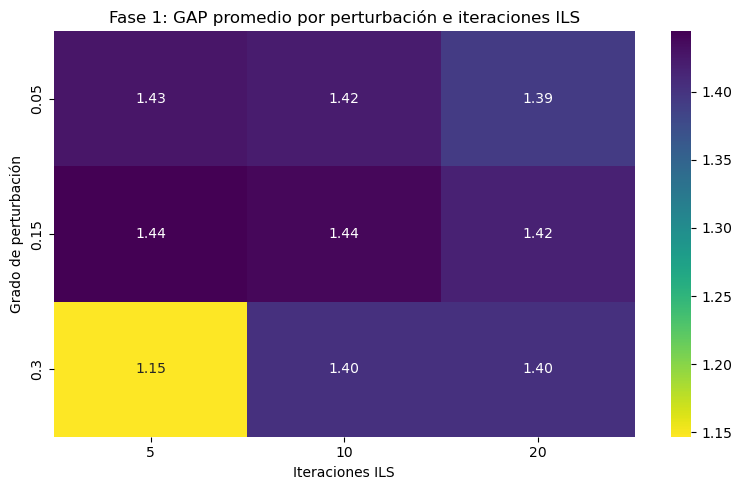

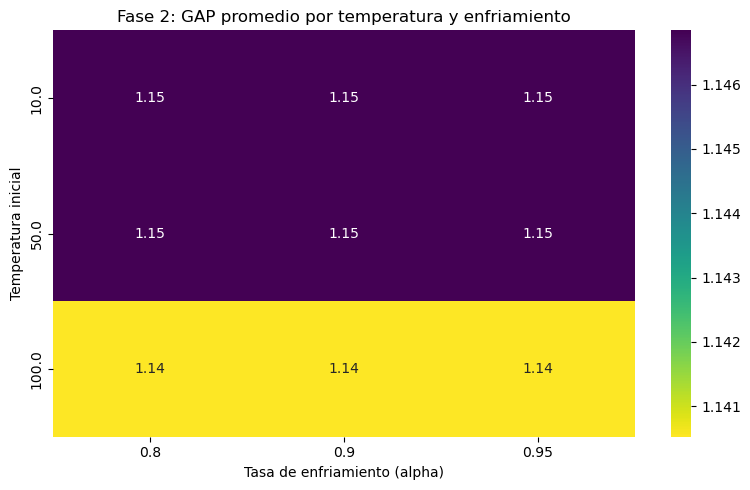

In [22]:

df_fase1["Gap_BKS (%)"] = pd.to_numeric(
    df_fase1["Gap_BKS (%)"], errors="coerce"
)
df_fase1["Tiempo"] = pd.to_numeric(
    df_fase1["Tiempo"], errors="coerce"
)


tabla_gap = df_fase1.pivot_table(
    index="Grado_Perturbacion",
    columns="Iters_ILS",
    values="Gap_BKS (%)",
    aggfunc="mean"
)

plt.figure(figsize=(8, 5))
sns.heatmap(
    tabla_gap,
    annot=True,
    fmt=".2f",
    cmap="viridis_r"
)
plt.title("Fase 1: GAP promedio por perturbación e iteraciones ILS")
plt.xlabel("Iteraciones ILS")
plt.ylabel("Grado de perturbación")
plt.tight_layout()
plt.show()

df_fase2["Gap_BKS (%)"] = pd.to_numeric(
    df_fase2["Gap_BKS (%)"], errors="coerce"
)
df_fase2["Tiempo"] = pd.to_numeric(
    df_fase2["Tiempo"], errors="coerce"
)


tabla_gap2 = df_fase2.pivot_table(
    index="T_Inicial",
    columns="Alpha",
    values="Gap_BKS (%)",
    aggfunc="mean"
)

plt.figure(figsize=(8, 5))
sns.heatmap(
    tabla_gap2,
    annot=True,
    fmt=".2f",
    cmap="viridis_r"
)
plt.title("Fase 2: GAP promedio por temperatura y enfriamiento")
plt.xlabel("Tasa de enfriamiento (alpha)")
plt.ylabel("Temperatura inicial")
plt.tight_layout()
plt.show()

#### Metaheuristica_hibrida

In [23]:
archivos_instancias = [f"GCP_{i}.txt" for i in range(1, 20)]
resultados_hibrido = {}
metodo_actual = "Hibrido_ILS_SA"

lista_vecindarios = [get_N1_neighbors, get_N2_neighbors, get_N3_neighbors]
random.seed(123)
np.random.seed(123)

for archivo in archivos_instancias:
    try:
        instancia = leer_instancia(archivo) 
        
        sol_final, z1_fin, z2_fin, f_obj_fin, t_exe_hib = metaheuristico_hibrido(
            instancia, 
            lista_vecindarios,
            num_inicios=3,
            grado_perturbacion=mejor_gp,
            iteraciones_ils=mejor_iters,      
            temp_inicial=mejor_ti,       
            alpha=mejor_alpha,              
            tiempo_max_segundos=3600
        )
        
        resultados_hibrido[archivo] = (sol_final, z1_fin, z2_fin, f_obj_fin, t_exe_hib)
        print(f"{archivo} | FO Final: {f_obj_fin:.2f} | z1: {z1_fin} | z2: {z2_fin} | Tiempo: {t_exe_hib:.2f}s")
        
    except FileNotFoundError:
        print(f"Advertencia: No se encontró {archivo}.")
    except Exception as e:
        print(f"Error procesando {archivo}: {e}")

print("\nGenerando reporte en Excel")
guardar_resultados_excel(resultados_hibrido, metodo_actual)

GCP_1.txt | FO Final: 403.79 | z1: 4 | z2: 23 | Tiempo: 0.04s
GCP_2.txt | FO Final: 405.44 | z1: 4 | z2: 33 | Tiempo: 0.04s
GCP_3.txt | FO Final: 900.00 | z1: 9 | z2: 0 | Tiempo: 0.32s
GCP_4.txt | FO Final: 7301.61 | z1: 73 | z2: 112 | Tiempo: 16.03s
GCP_5.txt | FO Final: 7301.90 | z1: 73 | z2: 132 | Tiempo: 14.63s
GCP_6.txt | FO Final: 1905.92 | z1: 19 | z2: 36 | Tiempo: 3.11s
GCP_7.txt | FO Final: 800.03 | z1: 8 | z2: 3 | Tiempo: 6.37s
GCP_8.txt | FO Final: 802.62 | z1: 8 | z2: 274 | Tiempo: 5.40s
GCP_9.txt | FO Final: 4901.56 | z1: 49 | z2: 171 | Tiempo: 27.97s
GCP_10.txt | FO Final: 4901.83 | z1: 49 | z2: 200 | Tiempo: 22.76s
GCP_11.txt | FO Final: 4901.10 | z1: 49 | z2: 124 | Tiempo: 46.41s
GCP_12.txt | FO Final: 4901.53 | z1: 49 | z2: 173 | Tiempo: 35.40s
GCP_13.txt | FO Final: 2001.02 | z1: 20 | z2: 142 | Tiempo: 6.83s
GCP_14.txt | FO Final: 1401.40 | z1: 14 | z2: 299 | Tiempo: 23.88s
GCP_15.txt | FO Final: 2800.29 | z1: 28 | z2: 67 | Tiempo: 58.36s
GCP_16.txt | FO Final: 2800.7

### Verificación de las soluciones

In [24]:
nombre_base = "GCP_JeronimoGil"
carpeta_solucionesanteriores = Path("soluciones_entregasanteriores")
archivos = {
    "Constructivo": carpeta_solucionesanteriores / f"{nombre_base}_constructivo.xlsx",
    "GRASP": carpeta_solucionesanteriores / f"{nombre_base}_GRASP.xlsx",
    "Ruido": carpeta_solucionesanteriores / f"{nombre_base}_Ruido.xlsx",
    "FI_N1": carpeta_solucionesanteriores / f"{nombre_base}_FI_N1.xlsx",
    "BI_N1": carpeta_solucionesanteriores / f"{nombre_base}_BI_N1.xlsx",
    "FI_N2": carpeta_solucionesanteriores / f"{nombre_base}_FI_N2.xlsx",
    "BI_N2": carpeta_solucionesanteriores / f"{nombre_base}_BI_N2.xlsx",
    "FI_N3": carpeta_solucionesanteriores / f"{nombre_base}_FI_N3.xlsx",
    "BI_N3": carpeta_solucionesanteriores / f"{nombre_base}_BI_N3.xlsx",
    "VND": Path(f"{nombre_base}_VND.xlsx"),
    "Hibrido_ILS_SA": Path(f"{nombre_base}_Hibrido_ILS_SA.xlsx")
}

resumen_validacion = {}
print("REVISIÓN DE FACTIBILIDAD")

for metodo, ruta in archivos.items():

    print(f"\n{metodo}")
    if not ruta.exists():

        print(f"No se encontró: {ruta}")
        resumen_validacion[metodo] = {
            "válidas": 0,
            "inválidas": 0,
            "total": 0,
            "estado": "ARCHIVO NO ENCONTRADO"
        }
        continue
    wb = openpyxl.load_workbook(
        ruta,
        data_only=True
    )

    validas = 0
    invalidas = 0
    errores = []
    for ws in wb.worksheets:
        nombre_instancia = ws.title
        fila_solucion = list(
            ws.iter_rows(
                min_row=1,
                max_row=1,
                values_only=True
            )
        )[0]

        solucion = list(fila_solucion)

        nombre_archivo_instancia = (
            f"{nombre_instancia}.txt"
        )
        try:
            instancia = leer_instancia(
                nombre_archivo_instancia
            )
        except Exception as e:

            invalidas += 1

            errores.append(
                (
                    nombre_instancia,
                    f"No se pudo cargar la instancia: {e}"
                )
            )

            continue

        es_valida, mensaje = validar_solucion(
            solucion,
            instancia
        )
        if es_valida:
            validas += 1
        else:
            invalidas += 1
            errores.append(
                (
                    nombre_instancia,
                    mensaje
                )
            )

    total = validas + invalidas
    if invalidas == 0 and total == 19:
        estado = "TODAS VÁLIDAS"

    elif invalidas == 0:
        estado = "VÁLIDAS, PERO FALTAN INSTANCIAS"
    else:
        estado = "HAY SOLUCIONES INVÁLIDAS"

    resumen_validacion[metodo] = {
        "válidas": validas,
        "inválidas": invalidas,
        "total": total,
        "estado": estado
    }

    print(f"Válidas   : {validas}")
    print(f"Inválidas : {invalidas}")
    print(f"Total     : {total}")
    print(f"Estado    : {estado}")
    if errores:
        print("\nProblemas encontrados:")
        for instancia, mensaje in errores:
            print(f"  {instancia}: {mensaje}")

print("\n")
print("RESUMEN DE LA VERIFICACIÓN")

for metodo, resultado in resumen_validacion.items():

    print(
        f"{metodo:15s} | "
        f"{resultado['válidas']:2d}/"
        f"{resultado['total']:2d} válidas | "
        f"{resultado['estado']}"
    )

todos_validos = all(
    resultado["válidas"] == 19
    and resultado["inválidas"] == 0
    for resultado in resumen_validacion.values()
    if resultado["total"] > 0
)
print("\n")
if todos_validos:

    print(
        "VERIFICACIÓN SUPERADA: "
        "todas las soluciones son factibles."
    )

else:

    print(
        "VERIFICACIÓN NO SUPERADA: "
        "existen resultados que no son factibles."
    )

REVISIÓN DE FACTIBILIDAD

Constructivo
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

GRASP
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

Ruido
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

FI_N1
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

BI_N1
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

FI_N2
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

BI_N2
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

FI_N3
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

BI_N3
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

VND
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS

Hibrido_ILS_SA
Válidas   : 19
Inválidas : 0
Total     : 19
Estado    : TODAS VÁLIDAS


RESUMEN DE LA VERIFICACIÓN
Constructivo    | 19/19 válidas | TODAS VÁLIDAS
GRASP           | 19/19 válidas | TOD

### Comparacion VND y Metaheuristico hibrido

#### Gap

In [25]:
nombre_base = "GCP_JeronimoGil"

metodos = [
    "VND",
    "Hibrido_ILS_SA"
]

archivos = {
    "VND": Path(f"{nombre_base}_VND.xlsx"),
    "Hibrido_ILS_SA": Path(f"{nombre_base}_Hibrido_ILS_SA.xlsx")
}

bks = {}
with open("BKS2.txt", "r", encoding="utf-8") as archivo:
    for i, linea in enumerate(archivo, start=1):
        linea = linea.strip()

        if linea:
            bks[f"GCP_{i}"] = float(linea.replace(",", "."))

datos = {}
for metodo, nombre_archivo in archivos.items():
    ruta = Path(nombre_archivo)
    if not ruta.exists():
        print(f"\nADVERTENCIA: no se encontró {nombre_archivo}")
        continue
    wb = openpyxl.load_workbook(
        nombre_archivo,
        data_only=True
    )
    datos[metodo] = {}
    for ws in wb.worksheets:

        instancia = ws.title
        fila = list(
            ws.iter_rows(
                min_row=2,
                max_row=2,
                values_only=True
            )
        )[0]

        z1 = fila[0]
        z2 = fila[1]
        fo = float(fila[2])
        tiempo = float(fila[3])
        bks_valor = bks[instancia]
        gap = 100 * (fo - bks_valor) / bks_valor
        datos[metodo][instancia] = {
            "z1": z1,
            "z2": z2,
            "fo": fo,
            "tiempo": tiempo,
            "bks": bks_valor,
            "gap": gap
        }

print("\nArchivos cargados correctamente.")

instancias = [f"GCP_{i}" for i in range(1, 20)]

tabla_gap = pd.DataFrame(
    index=instancias,
    columns=list(datos.keys()),
    dtype=float
)

for metodo in datos:

    for instancia in instancias:

        if instancia in datos[metodo]:

            tabla_gap.loc[
                instancia,
                metodo
            ] = datos[metodo][instancia]["gap"]

tabla_gap.loc["PROMEDIO"] = tabla_gap.mean()
print("GAP (%)")

display(tabla_gap.round(2))


Archivos cargados correctamente.
GAP (%)


,VND,Hibrido_ILS_SA
GCP_1,0.12,0.00
GCP_2,0.57,0.41
GCP_3,0.00,0.00
GCP_4,0.02,0.01
GCP_5,0.01,0.02
GCP_6,0.06,0.04
GCP_7,0.79,0.00
GCP_8,0.23,0.29
GCP_9,0.05,0.03
GCP_10,0.03,0.03


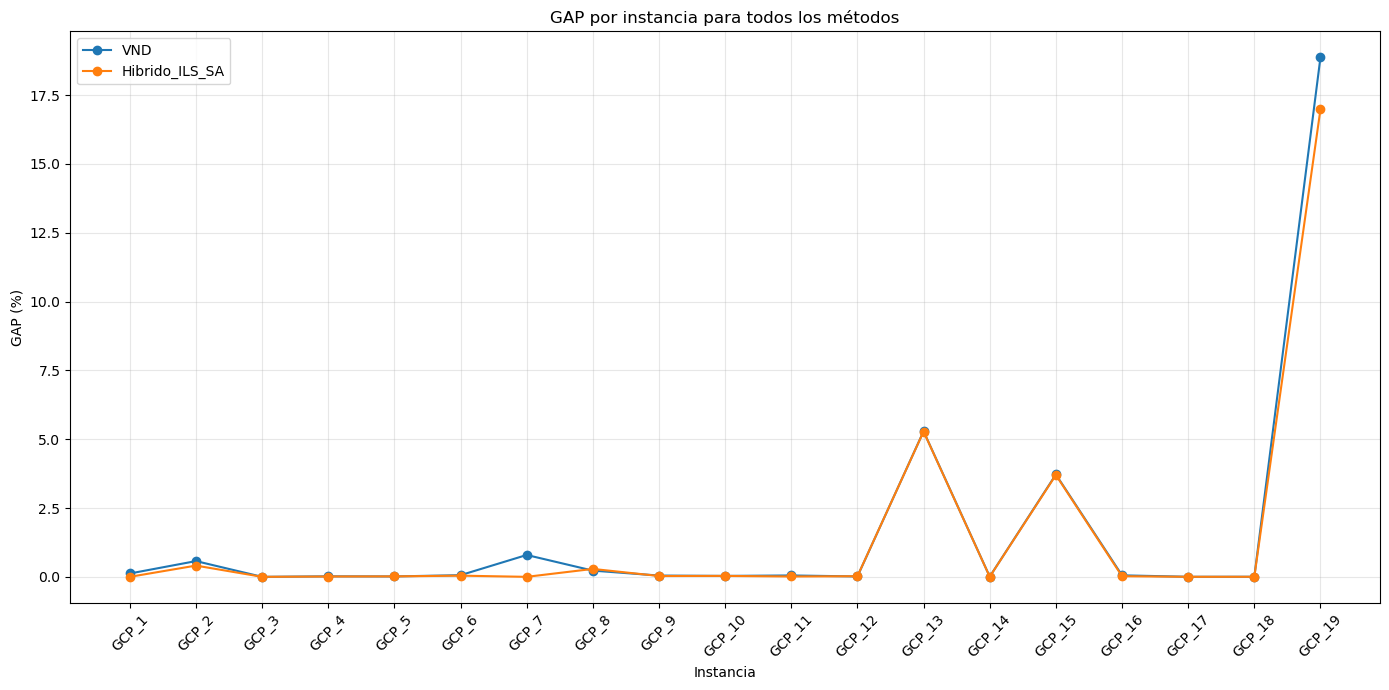

In [26]:
plt.figure(figsize=(14, 7))

for metodo in tabla_gap.columns:

    plt.plot(
        instancias,
        tabla_gap.loc[instancias, metodo],
        marker="o",
        label=metodo
    )

plt.xlabel("Instancia")
plt.ylabel("GAP (%)")
plt.title("GAP por instancia para todos los métodos")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Tiempo de computo

In [27]:
tabla_tiempo = pd.DataFrame(
    index=instancias,
    columns=list(datos.keys()),
    dtype=float
)

for metodo in datos:

    for instancia in instancias:

        if instancia in datos[metodo]:

            tabla_tiempo.loc[
                instancia,
                metodo
            ] = datos[metodo][instancia]["tiempo"]

tabla_tiempo.loc["PROMEDIO"] = tabla_tiempo.mean()

print("TIEMPO DE CÓMPUTO (s)")

display(tabla_tiempo.round(4))

TIEMPO DE CÓMPUTO (s)


,VND,Hibrido_ILS_SA
GCP_1,0.0000,0.0400
GCP_2,0.0000,0.0400
GCP_3,0.0000,0.3200
GCP_4,1.3900,16.0300
GCP_5,2.3800,14.6300
GCP_6,0.0200,3.1100
GCP_7,0.5800,6.3700
GCP_8,1.5100,5.4000
GCP_9,4.3000,27.9700
GCP_10,4.5600,22.7600


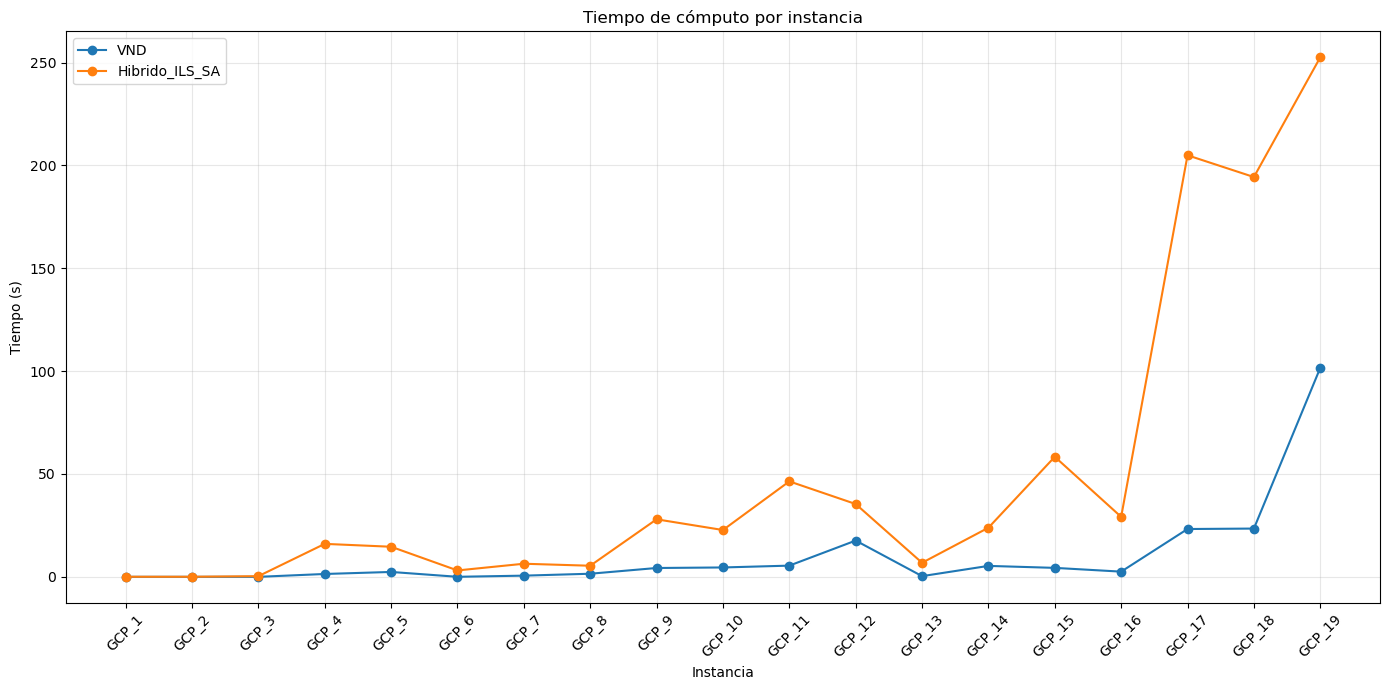

In [28]:
plt.figure(figsize=(14, 7))

for metodo in tabla_tiempo.columns:

    plt.plot(
        instancias,
        tabla_tiempo.loc[instancias, metodo],
        marker="o",
        label=metodo
    )

plt.xlabel("Instancia")
plt.ylabel("Tiempo (s)")
plt.title("Tiempo de cómputo por instancia")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Promedios

In [29]:
resumen = pd.DataFrame(index=list(datos.keys()))

resumen["GAP promedio (%)"] = [
    tabla_gap.loc["PROMEDIO", metodo]
    for metodo in datos.keys()
]

resumen["Tiempo promedio (s)"] = [
    tabla_tiempo.loc["PROMEDIO", metodo]
    for metodo in datos.keys()
]

display(resumen.round(4))

,GAP promedio (%),Tiempo promedio (s)
VND,1.5733,10.4574
Hibrido_ILS_SA,1.4136,49.9268


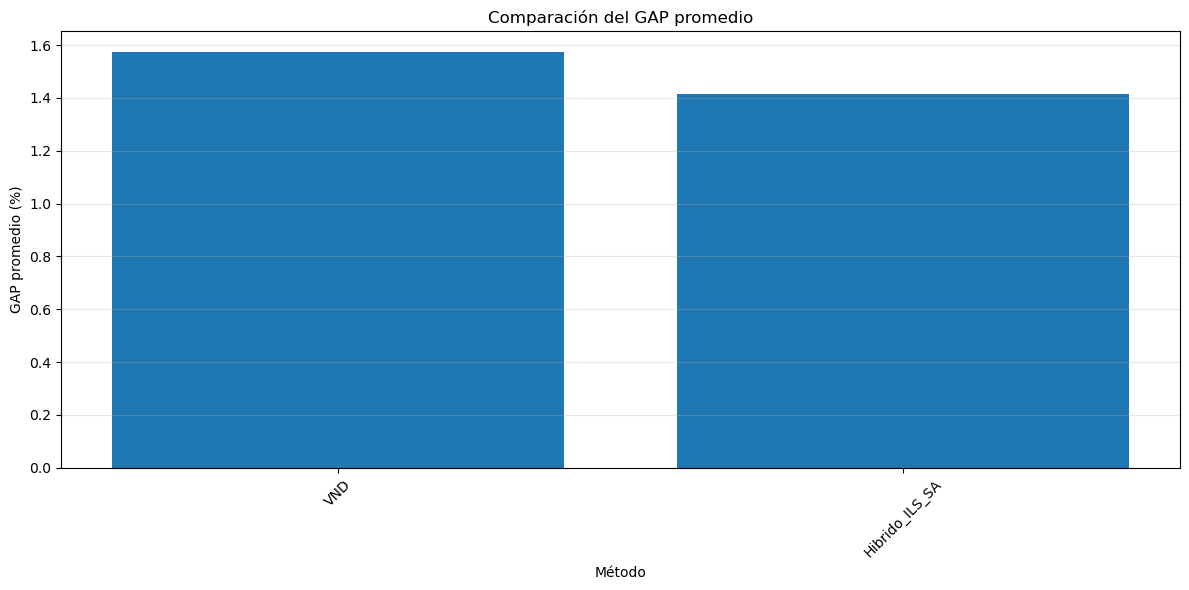

In [30]:
plt.figure(figsize=(12, 6))

plt.bar(
    resumen.index,
    resumen["GAP promedio (%)"]
)

plt.xlabel("Método")
plt.ylabel("GAP promedio (%)")
plt.title("Comparación del GAP promedio")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

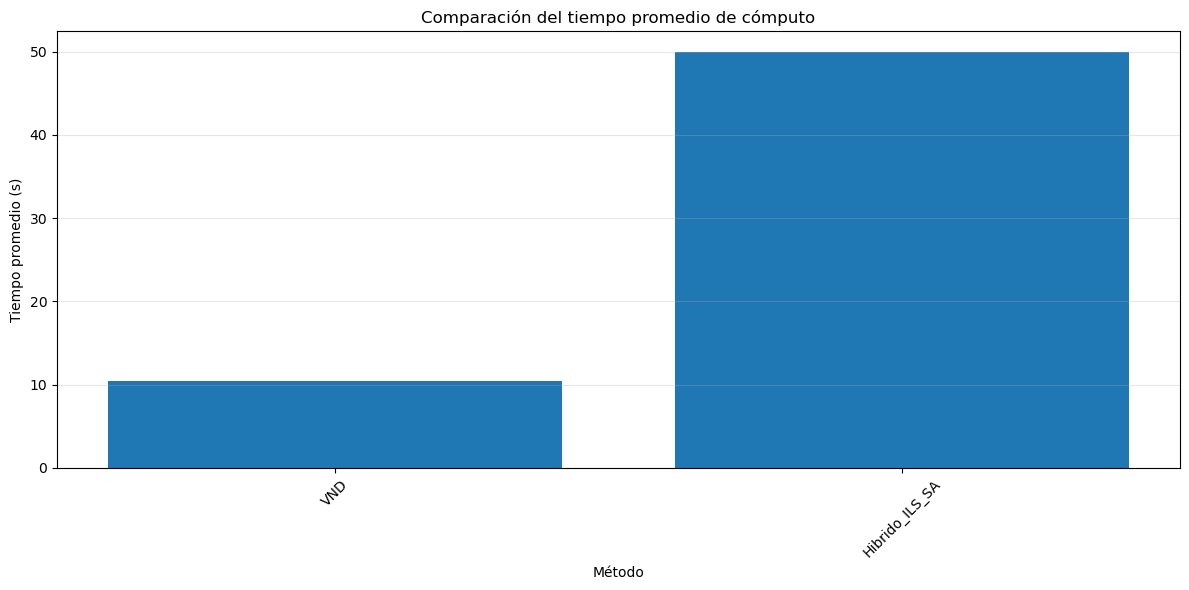

In [31]:
plt.figure(figsize=(12, 6))

plt.bar(
    resumen.index,
    resumen["Tiempo promedio (s)"]
)

plt.xlabel("Método")
plt.ylabel("Tiempo promedio (s)")
plt.title("Comparación del tiempo promedio de cómputo")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Comparaciones resultados anteriores

#### GAP

In [32]:
nombre_base = "GCP_JeronimoGil"

metodos = [
    "constructivo",
    "GRASP",
    "Ruido",
    "FI_N1",
    "FI_N2",
    "FI_N3",
    "BI_N1",
    "BI_N2",
    "BI_N3",
    "VND",
    "Hibrido_ILS_SA"
    
]

carpeta_solucionesanteriores = Path("soluciones_entregasanteriores")
archivos = {
    "Constructivo": carpeta_solucionesanteriores / f"{nombre_base}_constructivo.xlsx",
    "GRASP": carpeta_solucionesanteriores / f"{nombre_base}_GRASP.xlsx",
    "Ruido": carpeta_solucionesanteriores / f"{nombre_base}_Ruido.xlsx",
    "FI_N1": carpeta_solucionesanteriores / f"{nombre_base}_FI_N1.xlsx",
    "BI_N1": carpeta_solucionesanteriores / f"{nombre_base}_BI_N1.xlsx",
    "FI_N2": carpeta_solucionesanteriores / f"{nombre_base}_FI_N2.xlsx",
    "BI_N2": carpeta_solucionesanteriores / f"{nombre_base}_BI_N2.xlsx",
    "FI_N3": carpeta_solucionesanteriores / f"{nombre_base}_FI_N3.xlsx",
    "BI_N3": carpeta_solucionesanteriores / f"{nombre_base}_BI_N3.xlsx",
    "VND": Path(f"{nombre_base}_VND.xlsx"),
    "Hibrido_ILS_SA": Path(f"{nombre_base}_Hibrido_ILS_SA.xlsx")
}

bks = {}
with open("BKS2.txt", "r", encoding="utf-8") as archivo:
    for i, linea in enumerate(archivo, start=1):
        linea = linea.strip()

        if linea:
            bks[f"GCP_{i}"] = float(linea.replace(",", "."))

datos = {}
for metodo, nombre_archivo in archivos.items():
    ruta = Path(nombre_archivo)
    if not ruta.exists():
        print(f"\nADVERTENCIA: no se encontró {nombre_archivo}")
        continue
    wb = openpyxl.load_workbook(
        nombre_archivo,
        data_only=True
    )
    datos[metodo] = {}
    for ws in wb.worksheets:

        instancia = ws.title
        fila = list(
            ws.iter_rows(
                min_row=2,
                max_row=2,
                values_only=True
            )
        )[0]

        z1 = fila[0]
        z2 = fila[1]
        fo = float(fila[2])
        tiempo = float(fila[3])
        bks_valor = bks[instancia]
        gap = 100 * (fo - bks_valor) / bks_valor
        datos[metodo][instancia] = {
            "z1": z1,
            "z2": z2,
            "fo": fo,
            "tiempo": tiempo,
            "bks": bks_valor,
            "gap": gap
        }

print("\nArchivos cargados correctamente.")

instancias = [f"GCP_{i}" for i in range(1, 20)]

tabla_gap = pd.DataFrame(
    index=instancias,
    columns=list(datos.keys()),
    dtype=float
)

for metodo in datos:

    for instancia in instancias:

        if instancia in datos[metodo]:

            tabla_gap.loc[
                instancia,
                metodo
            ] = datos[metodo][instancia]["gap"]

tabla_gap.loc["PROMEDIO"] = tabla_gap.mean()
print("GAP (%)")

display(tabla_gap.round(2))


Archivos cargados correctamente.
GAP (%)


,Constructivo,GRASP,Ruido,FI_N1,BI_N1,FI_N2,BI_N2,FI_N3,BI_N3,VND,Hibrido_ILS_SA
GCP_1,5.63,3.55,6.65,0.57,0.57,4.77,3.67,1.63,2.41,0.12,0.00
GCP_2,6.24,4.12,5.51,0.57,0.57,3.84,3.84,5.51,5.51,0.57,0.41
GCP_3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
GCP_4,0.02,0.03,0.04,0.02,0.02,0.03,0.03,0.03,0.03,0.02,0.01
GCP_5,0.04,0.03,0.04,0.02,0.02,0.02,0.02,0.03,0.03,0.01,0.02
GCP_6,10.70,0.03,0.05,0.05,0.05,0.05,0.05,0.05,0.05,0.06,0.04
GCP_7,0.74,2.51,2.47,1.11,0.01,2.36,2.36,1.83,1.76,0.79,0.00
GCP_8,0.52,2.66,2.77,0.11,0.85,2.77,2.77,2.41,2.41,0.23,0.29
GCP_9,0.11,0.58,0.58,0.05,0.03,0.57,0.57,0.58,0.58,0.05,0.03
GCP_10,0.01,0.52,0.53,0.04,0.20,0.51,0.51,0.51,0.50,0.03,0.03


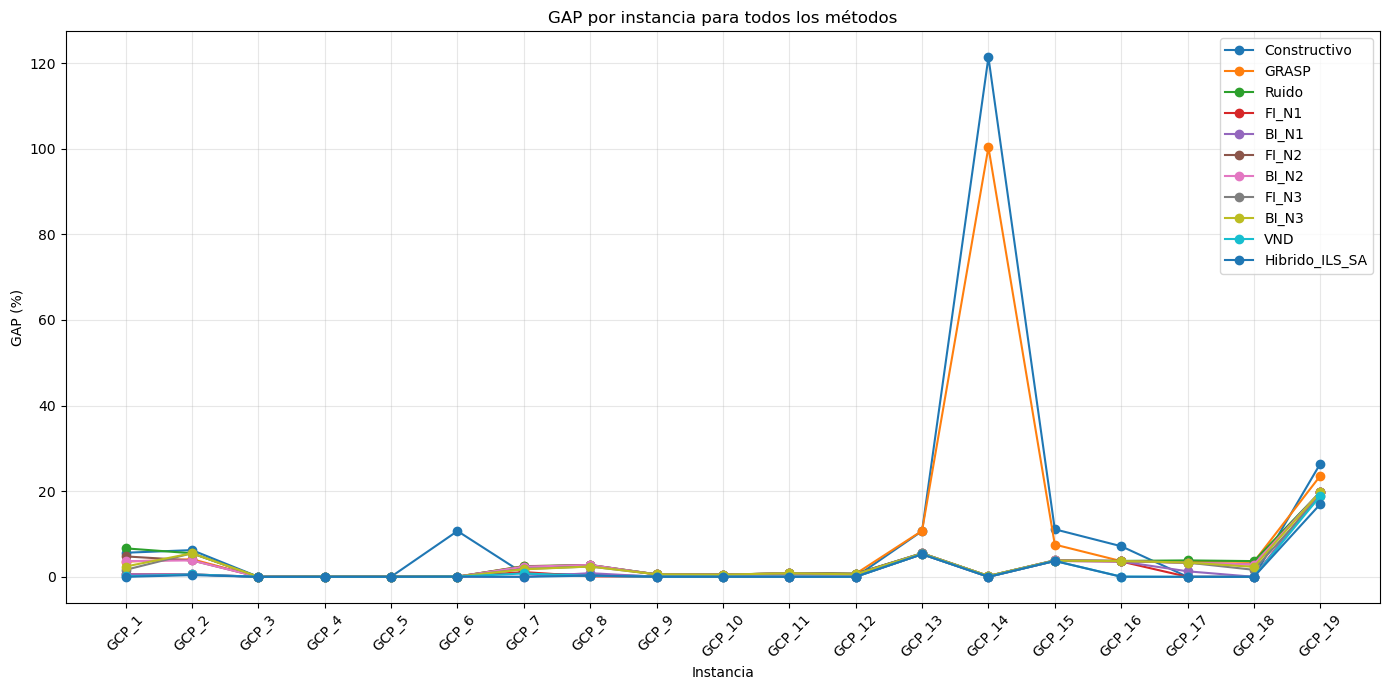

In [33]:
plt.figure(figsize=(14, 7))

for metodo in tabla_gap.columns:

    plt.plot(
        instancias,
        tabla_gap.loc[instancias, metodo],
        marker="o",
        label=metodo
    )

plt.xlabel("Instancia")
plt.ylabel("GAP (%)")
plt.title("GAP por instancia para todos los métodos")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Tiempo de computo

In [34]:
tabla_tiempo = pd.DataFrame(
    index=instancias,
    columns=list(datos.keys()),
    dtype=float
)

for metodo in datos:

    for instancia in instancias:

        if instancia in datos[metodo]:

            tabla_tiempo.loc[
                instancia,
                metodo
            ] = datos[metodo][instancia]["tiempo"]

tabla_tiempo.loc["PROMEDIO"] = tabla_tiempo.mean()

print("TIEMPO DE CÓMPUTO (s)")

display(tabla_tiempo.round(4))

TIEMPO DE CÓMPUTO (s)


,Constructivo,GRASP,Ruido,FI_N1,BI_N1,FI_N2,BI_N2,FI_N3,BI_N3,VND,Hibrido_ILS_SA
GCP_1,0.0000,0.01,0.0000,0.0000,0.0000,0.0000,0.00,0.0000,0.0000,0.0000,0.0400
GCP_2,0.0000,0.01,0.0000,0.0000,0.0000,0.0000,0.00,0.0000,0.0000,0.0000,0.0400
GCP_3,0.0100,0.10,0.0000,0.0000,0.0000,0.0000,0.00,0.0000,0.0000,0.0000,0.3200
GCP_4,0.1100,0.83,0.0000,0.1000,0.9600,0.0300,0.08,0.1300,0.2100,1.3900,16.0300
GCP_5,0.1100,0.53,0.0000,0.1300,0.4300,0.0300,0.07,0.1300,0.2600,2.3800,14.6300
GCP_6,0.0800,1.04,0.0000,0.0000,0.0000,0.0100,0.01,0.0000,0.0000,0.0200,3.1100
GCP_7,0.0500,1.12,0.0000,0.0600,0.5100,0.0200,0.05,0.0100,0.0300,0.5800,6.3700
GCP_8,0.0400,0.95,0.0000,0.1400,0.5100,0.0100,0.01,0.0000,0.0100,1.5100,5.4000
GCP_9,0.1600,1.23,0.0000,0.4000,14.9300,0.0400,0.18,0.0300,0.0300,4.3000,27.9700
GCP_10,0.1600,1.03,0.0000,0.2800,4.5800,0.0400,0.15,0.0300,0.0500,4.5600,22.7600


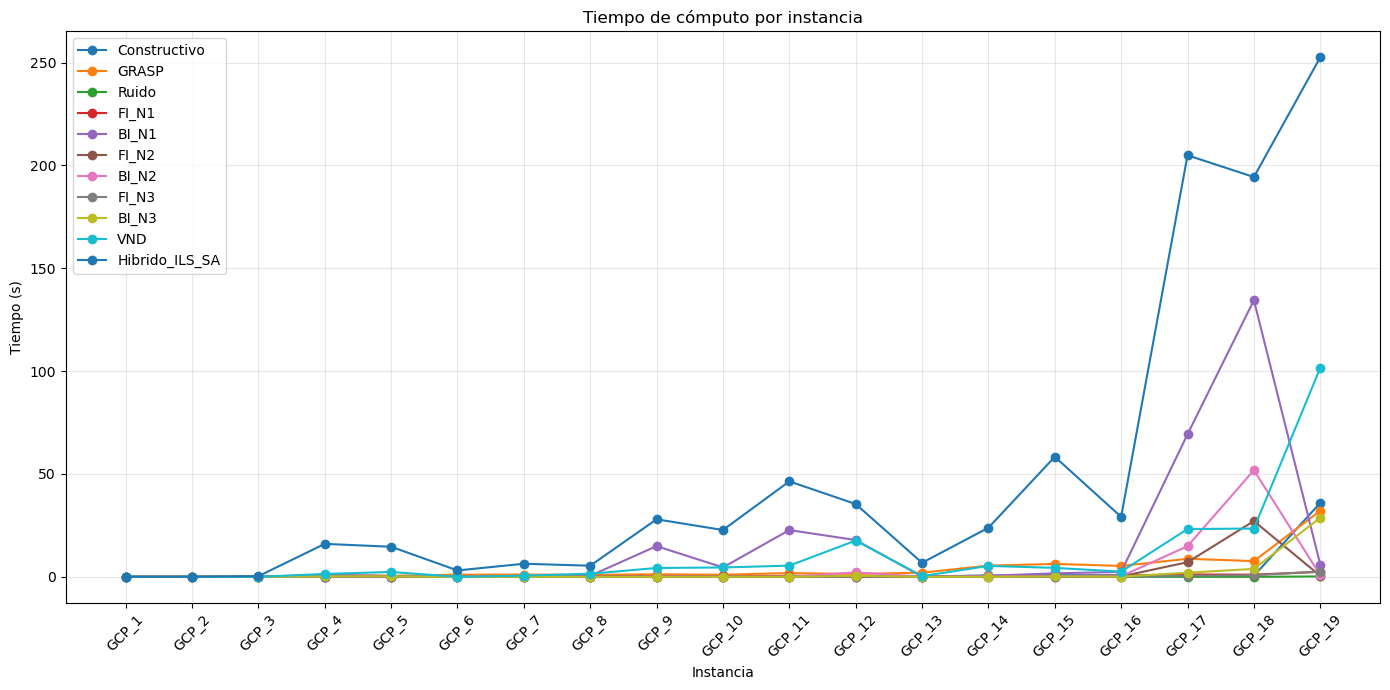

In [35]:
plt.figure(figsize=(14, 7))

for metodo in tabla_tiempo.columns:

    plt.plot(
        instancias,
        tabla_tiempo.loc[instancias, metodo],
        marker="o",
        label=metodo
    )

plt.xlabel("Instancia")
plt.ylabel("Tiempo (s)")
plt.title("Tiempo de cómputo por instancia")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Promedios

In [36]:
resumen = pd.DataFrame(index=list(datos.keys()))

resumen["GAP promedio (%)"] = [
    tabla_gap.loc["PROMEDIO", metodo]
    for metodo in datos.keys()
]

resumen["Tiempo promedio (s)"] = [
    tabla_tiempo.loc["PROMEDIO", metodo]
    for metodo in datos.keys()
]

display(resumen.round(4))

,GAP promedio (%),Tiempo promedio (s)
Constructivo,10.5658,2.1189
GRASP,8.8728,4.0900
Ruido,3.2014,0.0132
FI_N1,1.8461,0.4116
BI_N1,1.8995,14.5816
FI_N2,2.9281,1.8747
BI_N2,2.8592,3.7500
FI_N3,2.6858,0.2374
BI_N3,2.8055,1.8968
VND,1.5733,10.4574


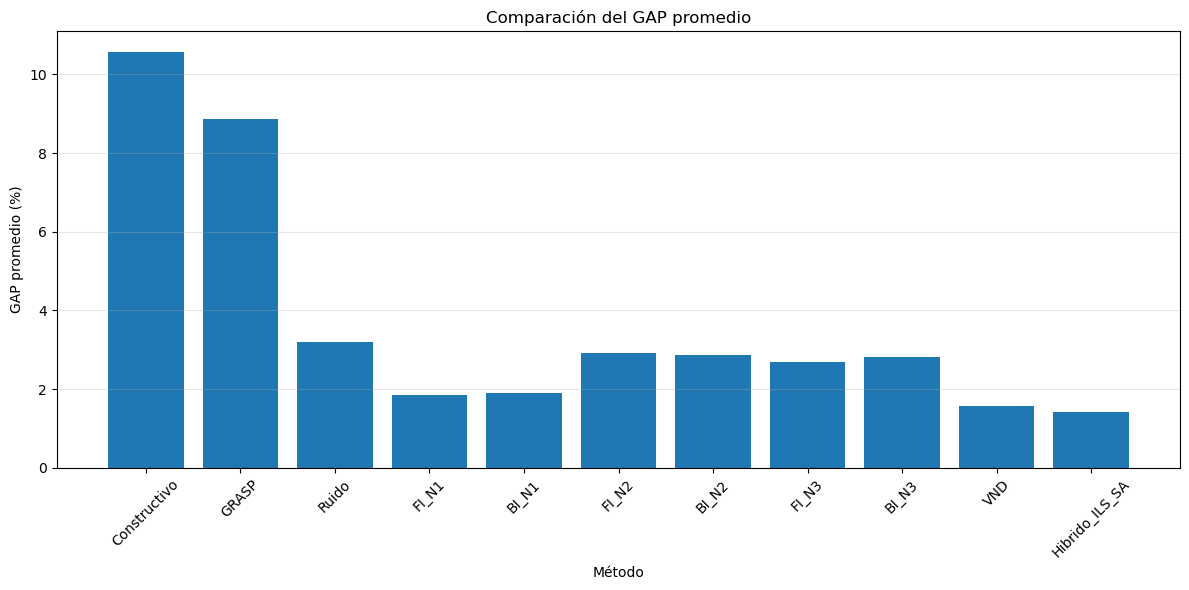

In [37]:
plt.figure(figsize=(12, 6))

plt.bar(
    resumen.index,
    resumen["GAP promedio (%)"]
)

plt.xlabel("Método")
plt.ylabel("GAP promedio (%)")
plt.title("Comparación del GAP promedio")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

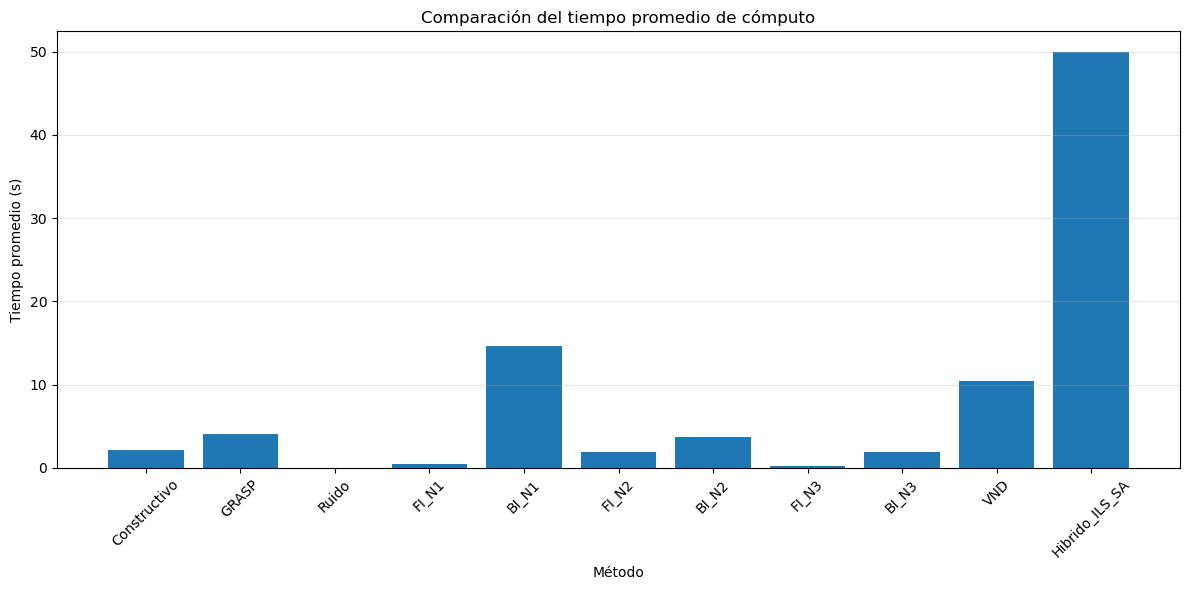

In [38]:
plt.figure(figsize=(12, 6))

plt.bar(
    resumen.index,
    resumen["Tiempo promedio (s)"]
)

plt.xlabel("Método")
plt.ylabel("Tiempo promedio (s)")
plt.title("Comparación del tiempo promedio de cómputo")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()